# 04 | Error, failure and operational analysis

This notebook performs the complete residual analysis and reconstructs policy summaries from retained case-level evidence. It covers metrics, horizon/fold errors, origin-safe high-load labels, regime onset/reversion, the final CV window, segment and individual errors, recorded holdout benchmark context, CPU-busy forecasts, probability calibration, low-use review policies, headroom and quantile readiness. It does not use new holdout scores to change the final model.

In [1]:
from pathlib import Path
import os,sys
import numpy as np
import pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
if not (ROOT/"src/cwfc").exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
os.environ["MPLCONFIGDIR"]=str(ROOT/"artifacts/.matplotlib")
from cwfc.analysis import run,summarize
tables=run(ROOT)


Fallback to a different backend


## 1. Metrics and units

MAE/RMSE are CPU percentage points; sMAPE uses an epsilon denominator. Bias is prediction minus actual. MASE scales each decision by that origin's historical one-step naive MAE; zero scales produce undefined ratios. MASE is not skill against the two-hour persistence forecast. Validation windows overlap; 168 decisions cover only 60 timestamps.

In [2]:
display(tables["overall"])
thresholds=tables["cases"][["origin","high_threshold","naive_scale"]].drop_duplicates()
display(thresholds)
assert tables["overall"].cases.eq(168).all()


,model,cases,mae,rmse,smape_pct,mase,bias,underforecast_fraction
0,global_vm_lightgbm,168,0.198813,0.268890,2.102033,1.592780,-0.096026,0.541667
1,vm_persistence,168,0.265502,0.317362,2.783430,2.115658,0.158328,0.244048


,origin,high_threshold,naive_scale
0,48,9.487372,0.122950
48,54,9.487166,0.125905
96,60,9.520936,0.123694
144,66,9.580335,0.127037
192,72,9.655610,0.126313
240,78,9.633523,0.127480
288,84,9.599249,0.124208


## 2. Horizon, fold and signed-bias failures

Both absolute error and direction matter. The first two origins underpredict the elevated-demand region; later folds forecast the return toward normal. Error need not increase monotonically with horizon because each step intersects different workload phases.

,step,model,cases,mae,rmse,smape_pct,mase,bias,underforecast_fraction
0,1,global_vm_lightgbm,7,0.120377,0.136638,1.266121,0.957390,0.059923,0.142857
1,1,vm_persistence,7,0.121215,0.153934,1.264711,0.962957,0.121215,0.000000
2,2,global_vm_lightgbm,7,0.182154,0.270632,1.909817,1.453054,-0.098787,0.571429
3,2,vm_persistence,7,0.143545,0.176271,1.491641,1.135698,0.058937,0.285714
4,3,global_vm_lightgbm,7,0.228723,0.280025,2.397993,1.823423,-0.171981,0.714286
5,3,vm_persistence,7,0.116948,0.134808,1.220306,0.930090,0.033858,0.285714
6,4,global_vm_lightgbm,7,0.219629,0.275258,2.314731,1.755581,-0.148948,0.714286
7,4,vm_persistence,7,0.149803,0.183537,1.570053,1.187497,0.108417,0.142857
8,5,global_vm_lightgbm,7,0.202433,0.289419,2.146177,1.615242,-0.067590,0.571429
9,5,vm_persistence,7,0.270733,0.285117,2.843186,2.155665,0.199703,0.142857


,fold,origin,model,cases,mae,rmse,smape_pct,mase,bias,underforecast_fraction
0,1,48,global_vm_lightgbm,24,0.399649,0.438360,4.204585,3.250494,-0.396864,0.958333
1,1,48,vm_persistence,24,0.298101,0.335599,3.115124,2.424571,-0.276592,0.875000
2,2,54,global_vm_lightgbm,24,0.402078,0.443756,4.231545,3.193502,-0.390188,0.916667
3,2,54,vm_persistence,24,0.159515,0.201947,1.657648,1.266948,0.001865,0.583333
4,3,60,global_vm_lightgbm,24,0.183183,0.231060,1.923248,1.480939,-0.132266,0.750000
5,3,60,vm_persistence,24,0.304821,0.362116,3.167112,2.464321,0.300305,0.083333
6,4,66,global_vm_lightgbm,24,0.092195,0.119412,0.978177,0.725735,0.002549,0.416667
7,4,66,vm_persistence,24,0.463836,0.495783,4.818361,3.651189,0.463836,0.000000
8,5,72,global_vm_lightgbm,24,0.104027,0.131345,1.112577,0.823562,0.084903,0.250000
9,5,72,vm_persistence,24,0.256934,0.281764,2.722971,2.034105,0.256934,0.000000


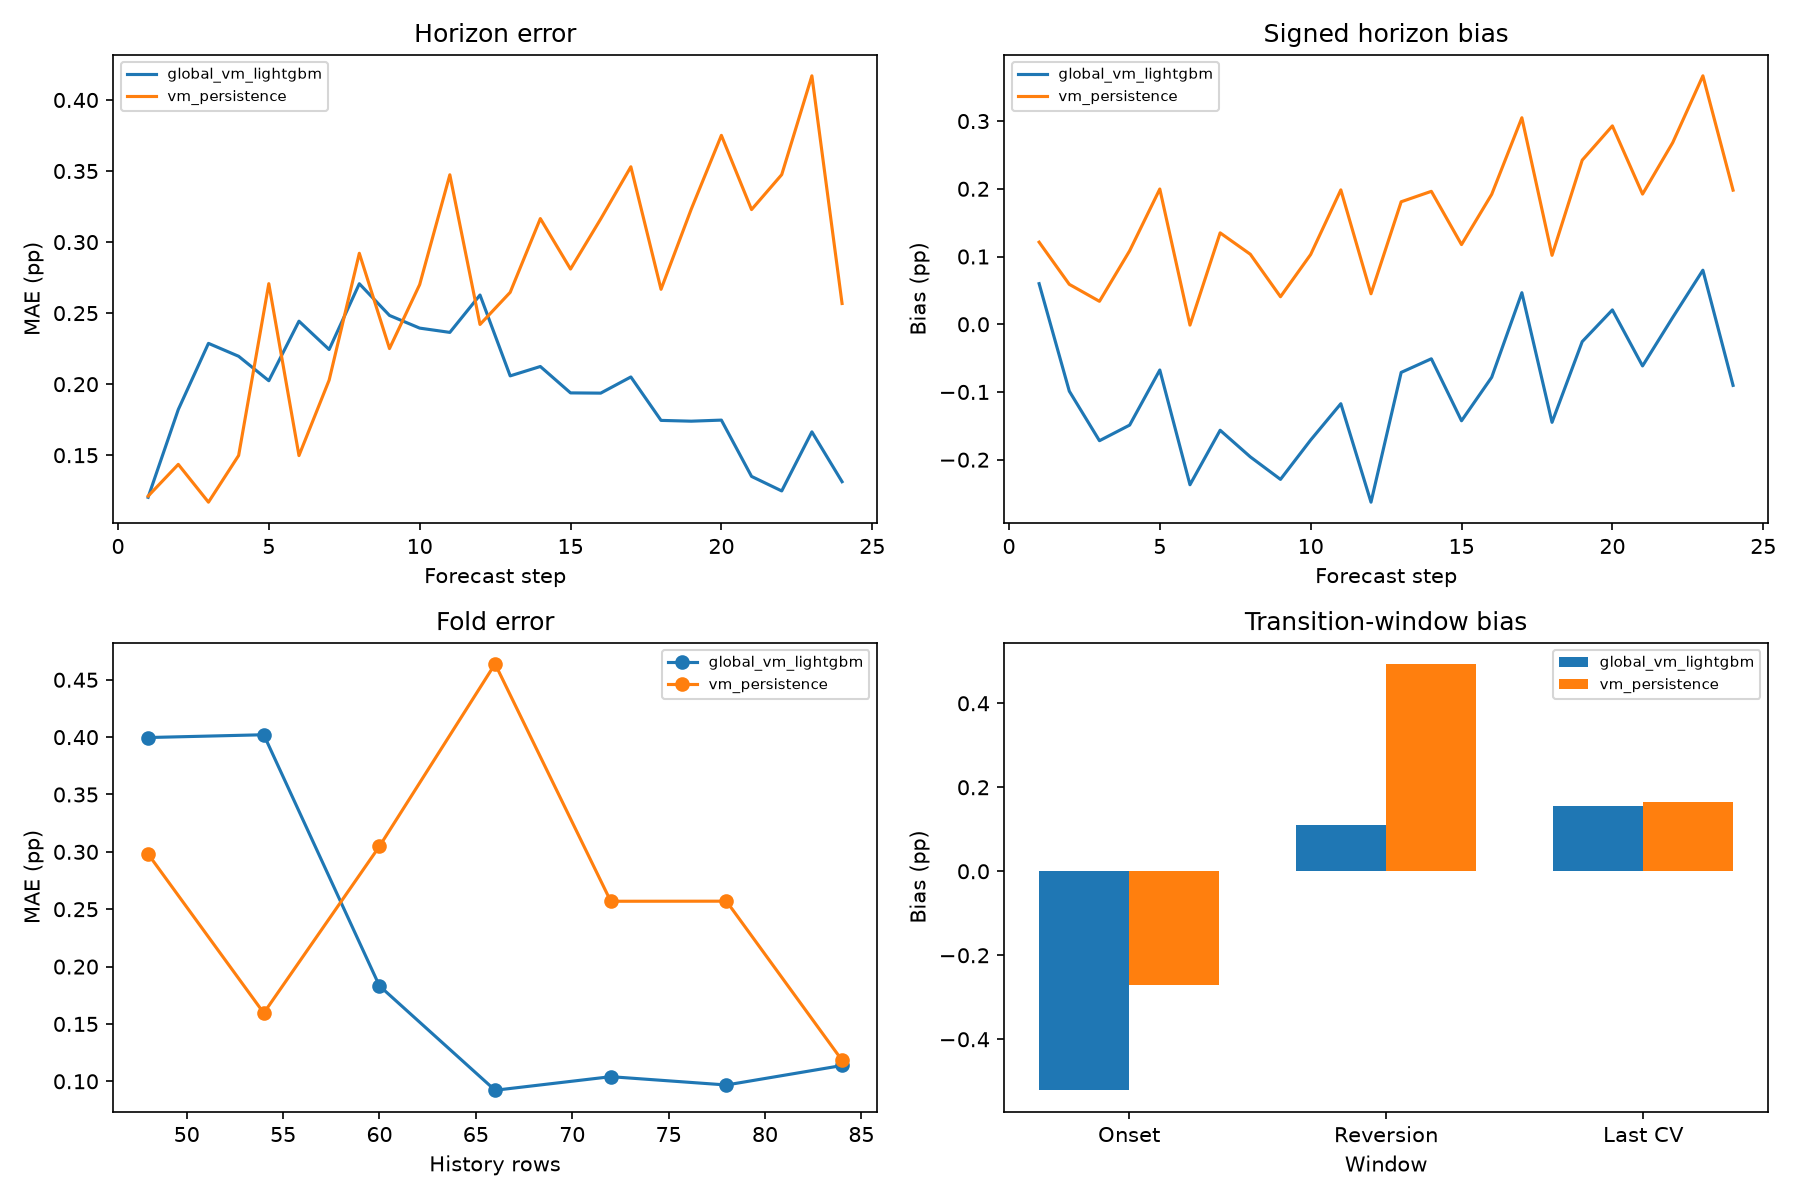

In [3]:
display(tables["by_horizon"])
display(tables["by_fold"])
display(Image(filename=str(ROOT/"reports/figures/final_error_analysis.png")))


## 3. Origin-safe high-load versus retrospective labels

The origin-safe diagnostic uses only each fold's history Q80. The separate retrospective diagnostic uses full-training Q80. These label different cases and must not be reported as the same experiment. Underprediction frequency is a CPU-demand proxy, not an observed SLA failure.

In [4]:
display(tables["by_load"])
retrospective=pd.read_csv(ROOT/"artifacts/final_model/error_breakdowns.csv")
display(retrospective.loc[retrospective.dimension.eq("regime")])


,load_period,model,cases,mae,rmse,smape_pct,mase,bias,underforecast_fraction
0,high_load,global_vm_lightgbm,58,0.388410,0.425137,4.077490,3.122995,-0.382259,0.965517
1,high_load,vm_persistence,58,0.213853,0.256457,2.215841,1.725010,-0.086366,0.603448
2,normal,global_vm_lightgbm,110,0.098844,0.122984,1.060428,0.785940,0.054897,0.318182
3,normal,vm_persistence,110,0.292735,0.345175,3.082705,2.321636,0.287349,0.054545


,dimension,value,model,cases,mae,rmse,bias,underforecast_fraction
62,regime,high_training_Q80,global_vm_lightgbm,60,0.372692,0.415694,-0.364054,0.933333
63,regime,high_training_Q80,vm_persistence,60,0.214281,0.258529,-0.070325,0.566667
64,regime,other,global_vm_lightgbm,108,0.102214,0.128332,0.052878,0.324074
65,regime,other,vm_persistence,108,0.293958,0.345748,0.285358,0.064815


## 4. Regime onset, mean reversion and last CV window

Window endpoints come from the strongest rise/fall of a trailing three-observation level over three steps, using training observations only. Inspect endpoint and preceding two observations. The last CV window stops at the last covered training index. No window is selected by model residuals.

In [5]:
display(tables["failure_windows"])
training=pd.read_csv(ROOT/"artifacts/workload_analysis/series.csv")
for event,group in tables["failure_windows"].groupby("event"):
    start,end=int(group.start_index.iloc[0]),int(group.end_index.iloc[0])
    stamps=training.timestamp.iloc[start:end+1]
    print(event)
    display(tables["cases"].loc[tables["cases"].timestamp.isin(stamps),
        ["origin","step","model","timestamp","y","yhat","load_period"]])


last_cv_window
mean_reversion
regime_onset


,model,cases,mae,rmse,smape_pct,mase,bias,underforecast_fraction,event,start_index,end_index
0,global_vm_lightgbm,6,0.521376,0.548274,5.462743,4.194568,-0.521376,1.000000,regime_onset,54,56
1,vm_persistence,6,0.286720,0.330509,2.970553,2.316208,-0.271608,0.833333,regime_onset,54,56
2,global_vm_lightgbm,12,0.124754,0.142520,1.341789,0.991905,0.110527,0.083333,mean_reversion,74,76
3,vm_persistence,12,0.493772,0.516914,5.194704,3.929170,0.493772,0.000000,mean_reversion,74,76
4,global_vm_lightgbm,3,0.155188,0.164901,1.673915,1.249422,0.155188,0.000000,last_cv_window,105,107
5,vm_persistence,3,0.165929,0.178726,1.788826,1.335898,0.165929,0.000000,last_cv_window,105,107


,origin,step,model,timestamp,y,yhat,load_period
309,84,22,global_vm_lightgbm,31500,9.280858,9.390609,normal
310,84,23,global_vm_lightgbm,31800,9.119565,9.353285,normal
311,84,24,global_vm_lightgbm,32100,9.218538,9.340631,normal
333,84,22,vm_persistence,31500,9.280858,9.372250,normal
334,84,23,vm_persistence,31800,9.119565,9.372250,normal
335,84,24,vm_persistence,32100,9.218538,9.372250,normal


,origin,step,model,timestamp,y,yhat,load_period
68,54,21,global_vm_lightgbm,22200,9.367732,9.282373,normal
69,54,22,global_vm_lightgbm,22500,9.233267,9.264925,normal
70,54,23,global_vm_lightgbm,22800,9.152754,9.263778,normal
92,54,21,vm_persistence,22200,9.367732,9.657586,normal
93,54,22,vm_persistence,22500,9.233267,9.657586,normal
94,54,23,vm_persistence,22800,9.152754,9.657586,normal
110,60,15,global_vm_lightgbm,22200,9.367732,9.401144,normal
111,60,16,global_vm_lightgbm,22500,9.233267,9.341979,normal
112,60,17,global_vm_lightgbm,22800,9.152754,9.369102,normal
134,60,15,vm_persistence,22200,9.367732,9.839981,normal


,origin,step,model,timestamp,y,yhat,load_period
6,48,7,global_vm_lightgbm,16200,9.612251,9.221110,high_load
7,48,8,global_vm_lightgbm,16500,9.912175,9.207210,high_load
8,48,9,global_vm_lightgbm,16800,9.853998,9.267175,high_load
30,48,7,vm_persistence,16200,9.612251,9.384814,high_load
31,48,8,vm_persistence,16500,9.912175,9.384814,high_load
32,48,9,vm_persistence,16800,9.853998,9.384814,high_load
48,54,1,global_vm_lightgbm,16200,9.612251,9.400665,high_load
49,54,2,global_vm_lightgbm,16500,9.912175,9.253662,high_load
50,54,3,global_vm_lightgbm,16800,9.853998,9.278771,high_load
72,54,1,vm_persistence,16200,9.612251,9.657586,high_load


## 5. Bottom-up segment errors for the final CPU model

Segment case tables were reconstructed from the saved final-model individual CV forecasts, joined to category/core/memory labels, and averaged within each segment. These are final-model diagnostics, not errors borrowed from the earlier segment regressor. Weighted segment predictions must reconcile to fleet predictions.

In [6]:
segments=pd.read_csv(ROOT/"artifacts/final_model/segment_cases.csv")
display(tables["segments"].loc[tables["segments"].model.eq("global_vm_lightgbm")].sort_values("mae",ascending=False).head(10))
weighted=segments.assign(total_prediction=segments.yhat*segments.vm_count).groupby(["fold","step","model"]).agg(
    total=("total_prediction","sum"),vms=("vm_count","sum"))
reconciled=weighted.total/weighted.vms
fleet=tables["cases"].set_index(["fold","step","model"]).yhat.reindex(reconciled.index)
np.testing.assert_allclose(reconciled,fleet,rtol=0,atol=1e-8)


,category,core_bucket,memory_bucket,model,cases,mae,rmse,smape_pct,mase,bias,underforecast_fraction
22,Interactive,2,32,global_vm_lightgbm,168,7.664815,8.465227,17.136977,NaN,7.585395,0.023810
52,Unknown,8,64,global_vm_lightgbm,168,3.845294,5.096375,49.776638,NaN,-3.820460,0.910714
36,Interactive,>24,>64,global_vm_lightgbm,168,2.051299,2.819108,26.377892,NaN,0.259835,0.333333
18,Delay-insensitive,>24,>64,global_vm_lightgbm,168,2.015607,2.941538,32.561329,NaN,-0.989967,0.428571
40,Unknown,2,4,global_vm_lightgbm,168,1.580632,1.765957,10.556514,NaN,1.539405,0.053571
26,Interactive,2,8,global_vm_lightgbm,168,1.412793,1.653439,9.493007,NaN,-1.239686,0.857143
16,Delay-insensitive,8,64,global_vm_lightgbm,168,1.082996,2.007926,7.004467,NaN,-0.429774,0.416667
44,Unknown,24,64,global_vm_lightgbm,168,0.821363,1.307095,19.167471,NaN,0.369617,0.154762
28,Interactive,24,64,global_vm_lightgbm,168,0.721738,0.845089,5.436526,NaN,0.702508,0.071429
42,Unknown,2,8,global_vm_lightgbm,168,0.701533,0.801719,6.520119,NaN,0.676343,0.029762


## 6. Individual VM and behavior-group errors

Aggregate averaging can conceal individual mistakes. Per-VM MAE percentiles describe the distribution of VM/origin errors, not forecast intervals. Behavior rules are assigned using history at each origin; they are descriptive groups rather than future-derived clusters.

In [7]:
display(pd.read_csv(ROOT/"artifacts/final_model/vm_error_distribution.csv"))
display(pd.read_csv(ROOT/"artifacts/final_model/behavior_scores.csv"))


,model,vm_origin_cases,macro_mae,median_vm_mae,p90_vm_mae,p99_vm_mae
0,global_vm_lightgbm,70000,2.133217,0.769886,4.493806,26.165843


,model,behavior,cases,sum_absolute_error,sum_square_error,sum_error,mae,rmse,bias
0,global_vm_lightgbm,low_average_bursty,17640,5.451263e+04,1.598290e+06,-12307.298987,3.090285,9.518720,-0.697693
1,global_vm_lightgbm,steady,767592,1.761743e+06,2.440100e+07,42028.766889,2.295155,5.638176,0.054754
2,global_vm_lightgbm,sustained_low_recent,28056,1.359192e+04,1.648617e+05,3347.324808,0.484457,2.424080,0.119309
3,global_vm_lightgbm,variable,866712,1.753957e+06,4.352875e+07,-194392.389393,2.023690,7.086808,-0.224287


## 7. Recorded holdout benchmark and final uptick

These are previously recorded persistence-benchmark observations retained for workload context. They are not final LightGBM holdout results. The final six steps show a local rise that a flat last-value forecast misses; this does not justify selecting or tuning LightGBM on the viewed holdout.

In [8]:
for name in ["recorded_holdout_scores","recorded_holdout_end_scores"]:
    recorded=pd.read_csv(ROOT/f"artifacts/comparison/{name}.csv")
    display(recorded.loc[recorded.model.eq("persistence")])
recorded=pd.read_csv(ROOT/"artifacts/comparison/recorded_holdout_cases.csv")
display(recorded.loc[recorded.model.eq("persistence") & recorded.step.gt(18)])


,target,model,forecast_cases,unique_timestamps,mae,rmse,smape_pct,mase,mase_cases,persistence_mae,skill_vs_persistence,bias,underforecast_fraction
0,active_vm_count,persistence,24,24,0.000000,0.000000,0.000000,NaN,0,0.000000,NaN,0.000000,0.000000
1,aggregate_cpu_utilization,persistence,24,24,0.146782,0.184785,1.585054,1.211906,24,0.146782,0.0,-0.104432,0.791667


,target,model,forecast_cases,unique_timestamps,mae,rmse,smape_pct,mase,mase_cases,persistence_mae,skill_vs_persistence,bias,underforecast_fraction
0,active_vm_count,persistence,6,6,0.000000,0.000000,0.00000,NaN,0,0.000000,NaN,0.000000,0.0
1,aggregate_cpu_utilization,persistence,6,6,0.253702,0.259963,2.72866,2.094684,6,0.253702,0.0,-0.253702,1.0


,timestamp,target,y,yhat,persistence_yhat,model,step,high_threshold,load_period,error,scaled_absolute_error
18,38400,active_vm_count,10000.000000,10000.000000,10000.000000,persistence,19,10000.000000,normal,0.000000,NaN
19,38700,active_vm_count,10000.000000,10000.000000,10000.000000,persistence,20,10000.000000,normal,0.000000,NaN
20,39000,active_vm_count,10000.000000,10000.000000,10000.000000,persistence,21,10000.000000,normal,0.000000,NaN
21,39300,active_vm_count,10000.000000,10000.000000,10000.000000,persistence,22,10000.000000,normal,0.000000,NaN
22,39600,active_vm_count,10000.000000,10000.000000,10000.000000,persistence,23,10000.000000,normal,0.000000,NaN
23,39900,active_vm_count,10000.000000,10000.000000,10000.000000,persistence,24,10000.000000,normal,0.000000,NaN
42,38400,aggregate_cpu_utilization,9.421044,9.164556,9.164556,persistence,19,9.554494,normal,-0.256488,2.117689
43,38700,aggregate_cpu_utilization,9.430236,9.164556,9.164556,persistence,20,9.554494,normal,-0.265680,2.193577
44,39000,aggregate_cpu_utilization,9.307138,9.164556,9.164556,persistence,21,9.554494,normal,-0.142581,1.177219
45,39300,aggregate_cpu_utilization,9.499973,9.164556,9.164556,persistence,22,9.554494,normal,-0.335417,2.769361


## 8. Observed population versus CPU-busy demand

Observed count is based on valid VM readings. Busy count counts CPU-threshold events; expected busy count sums classifier probabilities. Thresholding a predicted conditional mean estimates a different quantity. Compare thresholds 0.1%, 1% and 5% without treating busy counts as required capacity.

,model,forecast_cases,mae,rmse,bias,smape_pct,underforecast_fraction,threshold
0,busy_count_ma3,168,1.351190,1.683840,-0.113095,0.013548,0.428571,0.1
1,busy_count_persistence,168,1.684524,2.065879,-1.208333,0.016890,0.672619,0.1
2,cpu_threshold_count,168,21.232143,21.304622,21.232143,0.212657,0.000000,0.1
3,busy_count_ma3,168,11.565476,14.084143,-0.494048,0.125171,0.505952,1.0
4,busy_probability_model,168,14.041272,17.539427,-2.426898,0.151995,0.500000,1.0
5,busy_count_persistence,168,14.220238,17.645821,8.315476,0.153862,0.327381,1.0
6,cpu_threshold_count,168,313.208333,314.626356,313.208333,3.333057,0.000000,1.0
7,busy_count_ma3,168,52.101190,60.936133,23.065476,1.018859,0.345238,5.0
8,busy_count_persistence,168,86.244048,99.204125,79.113095,1.679670,0.113095,5.0
9,cpu_threshold_count,168,375.059524,380.702937,375.059524,7.090755,0.000000,5.0


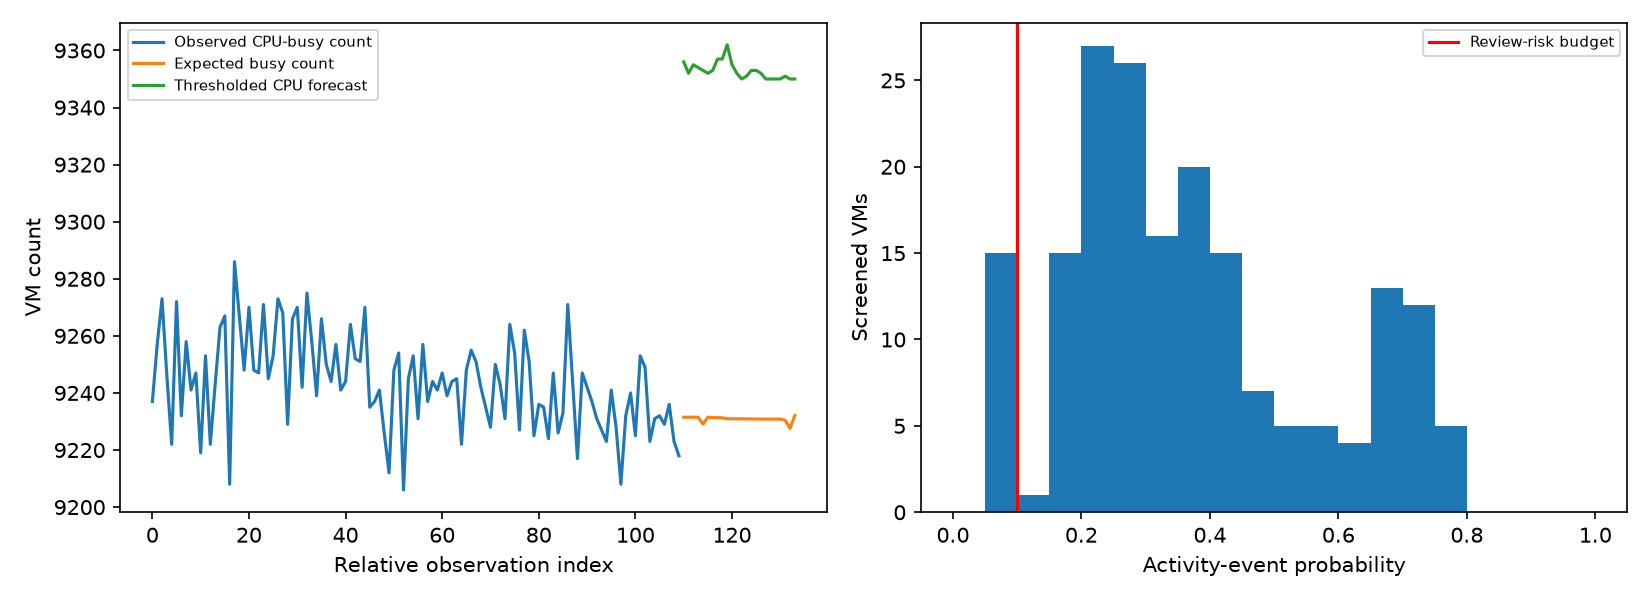

In [9]:
busy=pd.read_csv(ROOT/"artifacts/operational/busy_count_scores.csv")
display(busy)
display(Image(filename=str(ROOT/"reports/figures/operational_activity.png")))


## 9. Probability calibration and delayed event labels

Busy outcomes mature at their timestamp; two-hour event labels require the whole 24-step window. Platt calibration uses only matured earlier-origin out-of-fold probabilities. Early folds may serve raw probabilities. Inspect raw and served Brier/log loss and reliability; calibration does not imply a risk guarantee.

,target,stream,cases,sum_brier,sum_log_loss,brier_score,log_loss
0,busy_at_horizon,raw,1680000,22725.770575,76952.433948,0.013527,0.045805
1,busy_at_horizon,served,1680000,22771.689579,77381.396918,0.013555,0.046060
2,two_hour_activity_given_screen,raw,1169,270.157205,833.637057,0.231101,0.713120
3,two_hour_activity_given_screen,served,1169,260.859247,800.215385,0.223147,0.684530


,origin,target,calibrated,probability_bin,cases,mean_probability,observed_event_fraction,stream
0,48,busy_at_horizon,False,0,8739,0.049780,0.032498,raw
1,48,busy_at_horizon,False,1,4403,0.153672,0.118101,raw
2,48,busy_at_horizon,False,2,3051,0.242904,0.221239,raw
3,48,busy_at_horizon,False,3,1439,0.351274,0.307853,raw
4,48,busy_at_horizon,False,4,1352,0.453229,0.436391,raw
...,...,...,...,...,...,...,...,...
267,84,two_hour_activity_given_screen,True,3,34,0.341957,0.294118,served
268,84,two_hour_activity_given_screen,True,4,32,0.446698,0.187500,served
269,84,two_hour_activity_given_screen,True,5,36,0.538006,0.305556,served
270,84,two_hour_activity_given_screen,True,6,24,0.653010,0.708333,served


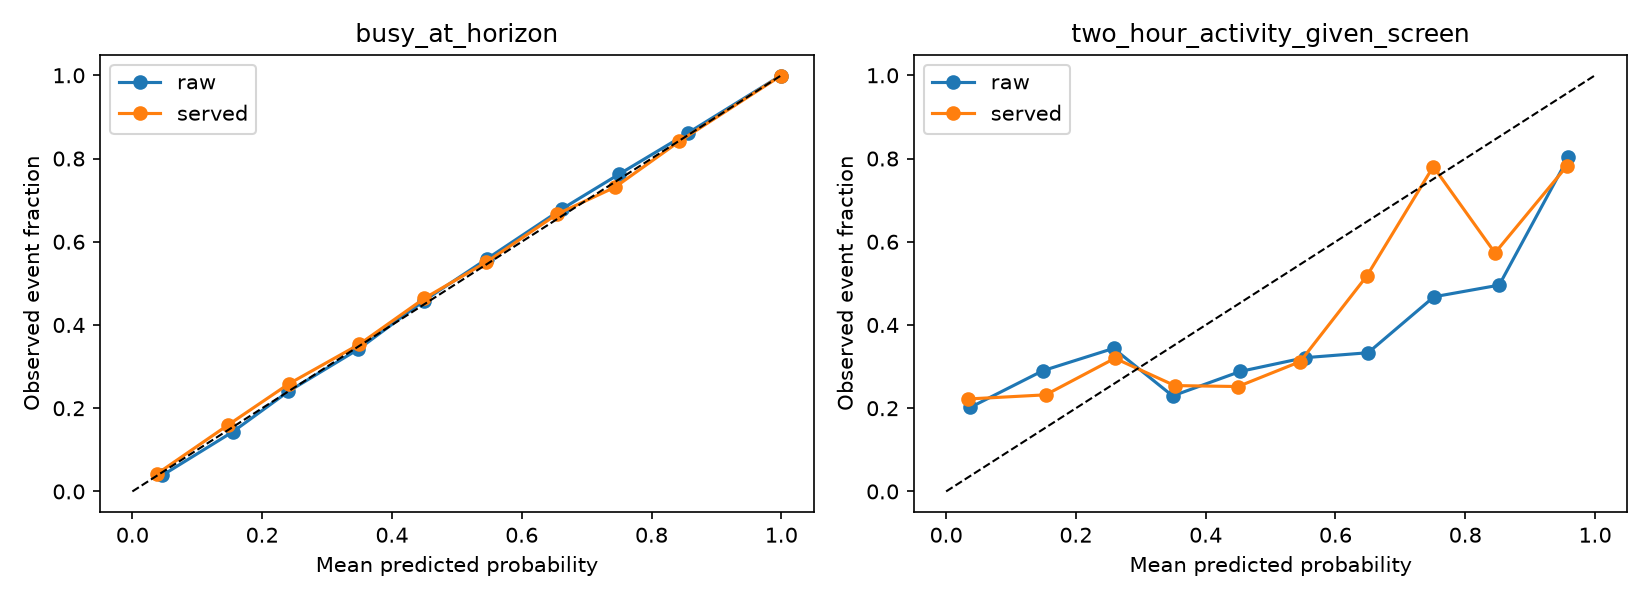

In [10]:
display(pd.read_csv(ROOT/"artifacts/operational/probability_summary.csv"))
display(pd.read_csv(ROOT/"artifacts/operational/probability_reliability.csv"))
display(Image(filename=str(ROOT/"reports/figures/probability_calibration.png")))


## 10. Low-use screen, matched-count policies and hysteresis

Require all last 12 averages below 1% and maxima below 5%. Future activity is any crossing in the next 24 slots. The risk budget is 0.1; matched recent-average and recent-peak baselines select equal numbers. Hysteresis enters at 0.1 and exits at 0.2. Candidate precision means staying below both thresholds throughout the complete future window.

In [11]:
display(tables["candidate_policy_summary"])
decisions=pd.read_csv(ROOT/"artifacts/operational/candidate_policy.csv")
display(decisions)
shortlist=pd.read_csv(ROOT/"artifacts/operational/low_use_review_candidates.csv")
display(shortlist)
assert len(shortlist)==186
assert shortlist.review_candidate.sum()==15


,policy,candidate_decisions,future_activity_events,stable_candidate_decisions,candidate_vm_hours,switches,candidate_precision
0,keep_all,0,0,0,0.0,0.0,NaN
1,lowest_average_matched_0.05,122,19,103,244.0,47.0,0.844262
2,lowest_average_matched_0.1,180,38,142,360.0,77.0,0.788889
3,lowest_average_matched_0.2,292,65,227,584.0,113.0,0.777397
4,lowest_average_matched_0.4,456,116,340,912.0,134.0,0.745614
5,lowest_peak_matched_0.05,122,20,102,244.0,51.0,0.836066
6,lowest_peak_matched_0.1,180,41,139,360.0,73.0,0.772222
7,lowest_peak_matched_0.2,292,65,227,584.0,99.0,0.777397
8,lowest_peak_matched_0.4,456,107,349,912.0,132.0,0.765351
9,risk_hysteresis,240,48,192,480.0,71.0,0.800000


,origin,policy,candidate_decisions,future_activity_events,stable_candidate_decisions,candidate_precision,safe_opportunity_captured,candidate_vm_hours,switches_since_previous_origin,scope
0,48,keep_all,0,0,0,NaN,0.000000,0.0,NaN,"CPU-threshold review opportunities, not verifi..."
1,48,screen_only,168,82,86,0.511905,0.781818,336.0,NaN,"CPU-threshold review opportunities, not verifi..."
2,48,risk_le_0.05,39,7,32,0.820513,0.290909,78.0,NaN,"CPU-threshold review opportunities, not verifi..."
3,48,lowest_average_matched_0.05,39,6,33,0.846154,0.300000,78.0,NaN,"CPU-threshold review opportunities, not verifi..."
4,48,lowest_peak_matched_0.05,39,9,30,0.769231,0.272727,78.0,NaN,"CPU-threshold review opportunities, not verifi..."
...,...,...,...,...,...,...,...,...,...,...
100,84,lowest_peak_matched_0.2,15,0,15,1.000000,0.118110,30.0,3.0,"CPU-threshold review opportunities, not verifi..."
101,84,risk_le_0.4,57,11,46,0.807018,0.362205,114.0,21.0,"CPU-threshold review opportunities, not verifi..."
102,84,lowest_average_matched_0.4,57,10,47,0.824561,0.370079,114.0,23.0,"CPU-threshold review opportunities, not verifi..."
103,84,lowest_peak_matched_0.4,57,6,51,0.894737,0.401575,114.0,19.0,"CPU-threshold review opportunities, not verifi..."


,vm_id,forecast_origin_timestamp,event_window_end_timestamp,last_hour_mean_cpu,last_hour_max_cpu,future_activity_risk_raw,future_activity_risk,review_candidate
0,03PBTTDZjmlgdQ6WT3vtOO09QnCTBGnCCVNJw9Hg9+Cw/A...,32700,39900,0.052229,0.077789,0.003854,0.068365,True
1,8UlIJ2BmALS2d5hh8HjWRyfzWAHxsVoatHHhtmiHc2wqtY...,32700,39900,0.041365,0.058922,0.003854,0.068365,True
2,BoUD7d3aCOjg6yDP7rpRSVgYWT3Ky43zD1159vBtUq124J...,32700,39900,0.048249,0.062327,0.003854,0.068365,True
3,JJCAw3k+D1pyJMBjhUQeFIop0y8peNGc+IKe36BU6T6gRO...,32700,39900,0.043523,0.054953,0.003854,0.068365,True
4,glxRrgvnIY5vH5QYg5uhv64Cv/0Z5n3i5yMAym0h6YD5Zd...,32700,39900,0.010808,0.024739,0.003854,0.068365,True
...,...,...,...,...,...,...,...,...
181,Z1UUi1HHYvWoNNgVMuhP3YWdt6nMRl+fnhgslcCO10UyLE...,32700,39900,0.489214,3.945898,0.976258,0.762799,False
182,nBgdPbOd6gu56vLGMRc2KfmM8E62p/1DxsLDX9QFhT2N1z...,32700,39900,0.524387,3.812481,0.976513,0.763612,False
183,N72H4ipqb1/EQjIvMQsJqGE/thqWt1XJUDDgp5ctGISVmp...,32700,39900,0.666953,4.831833,0.976825,0.764618,False
184,F8G7GLu8Pohh55jRJLjLFUVJCwKuYAdUH6x3Lvwp3ez5ul...,32700,39900,0.574923,4.920741,0.978631,0.770655,False


**Interpretation:** the risk-0.1 rule has 22.2% observed activity events and precision 77.8%, versus 78.9% for matched recent-average selection. This does not establish a better automatic shutdown rule. The screen alone admits 500 events across 1,169 repeated decisions. Overlapping candidate VM-hours are opportunities, not additive realized savings. Memory, ownership, replica, state and recovery constraints still need review.

## 11. Selected-model headroom and idle-capacity trade-off

Compare 0/0.25/0.5 pp fixed buffers with an empirical upper residual margin. Calibration uses earlier matured residuals in six-step bands, requiring 12 residuals and using a declared 0.5 pp warmup margin. Cost is `5*shortfall + excess`. These are assumed utilization-proxy costs, not money or measured SLA penalties.

In [12]:
display(tables["headroom_summary"])
headroom=pd.read_csv(ROOT/"artifacts/operational/headroom_backtest.csv")
display(headroom.groupby(["policy","margin_source"]).size().rename("decisions").reset_index())
assert (headroom.cost_proxy-(5*headroom.underforecast+headroom.excess_headroom_pp)).abs().max()<1e-8


,policy,cases,underforecast_fraction,mean_shortfall_pp,mean_excess_headroom_pp,mean_cost_proxy
0,empirical_upper,168,0.107143,0.009617,0.454440,0.502525
1,fixed_0.25pp,168,0.279762,0.055803,0.209777,0.488793
2,fixed_0.5pp,168,0.107143,0.009617,0.413591,0.461676
3,fixed_0pp,168,0.541667,0.147420,0.051394,0.788491


,policy,margin_source,decisions
0,empirical_upper,empirical_matured_residuals,84
1,empirical_upper,fixed_warmup_margin,84
2,fixed_0.25pp,fixed,168
3,fixed_0.5pp,fixed,168
4,fixed_0pp,fixed,168


## 12. Exact-horizon category quantile readiness

The retained category-persistence scenarios are separate from the selected-model headroom experiment. P90 needs nine matured residuals per horizon; seven folds are insufficient. Unsupported bounds use 100%, making zero shortfalls economically uninformative. Fixed buffers remain comparators, and a slope trigger is an inspection alert. No distribution-free coverage or SLA-safe automatic provisioning rule is established.

,target,model,policy,forecast_cases,unique_timestamps,under_provision_rate,mean_shortfall_pp,mean_over_provision_pp,mean_cost_proxy,upper_coverage,interval_coverage,mean_pinball_pp,supported_fraction,mean_calibration_n,peak_trigger_fraction
0,Delay-insensitive,category_persistence,cost_ratio_default,168,60,0.000000,0.000000,59.245226,59.245226,1.000000,0.964286,14.772058,0.357143,1.857143,0.142857
1,Delay-insensitive,category_persistence,cost_ratio_peak_trigger,168,60,0.000000,0.000000,59.245226,59.245226,1.000000,0.964286,14.772058,0.357143,1.857143,0.142857
2,Delay-insensitive,category_persistence,fixed_0.25pp,168,60,0.172619,0.034013,0.396301,0.498340,NaN,NaN,NaN,0.000000,0.000000,0.142857
3,Delay-insensitive,category_persistence,fixed_0.5pp,168,60,0.065476,0.007938,0.620227,0.644042,NaN,NaN,NaN,0.000000,0.000000,0.142857
4,Delay-insensitive,category_persistence,fixed_0pp,168,60,0.333333,0.088416,0.200705,0.465954,NaN,NaN,NaN,0.000000,0.000000,0.142857
5,Delay-insensitive,category_persistence,quantile_0.5,168,60,0.000000,0.000000,33.254167,33.254167,0.916667,0.845238,16.499262,0.642857,1.857143,0.142857
6,Delay-insensitive,category_persistence,quantile_0.75,168,60,0.000000,0.000000,59.245226,59.245226,1.000000,0.964286,14.772058,0.357143,1.857143,0.142857
7,Delay-insensitive,category_persistence,quantile_0.9,168,60,0.000000,0.000000,91.662653,91.662653,1.000000,1.000000,9.166265,0.000000,1.857143,0.142857
8,Interactive,category_persistence,cost_ratio_default,168,60,0.000000,0.000000,88.405148,88.405148,1.000000,1.000000,8.840515,0.000000,1.857143,0.571429
9,Interactive,category_persistence,cost_ratio_peak_trigger,168,60,0.000000,0.000000,88.405148,88.405148,1.000000,1.000000,8.840515,0.000000,1.857143,0.571429


,minimum_residuals,supported_steps
target,,
Delay-insensitive,7,24
Interactive,7,0
Unknown,7,24


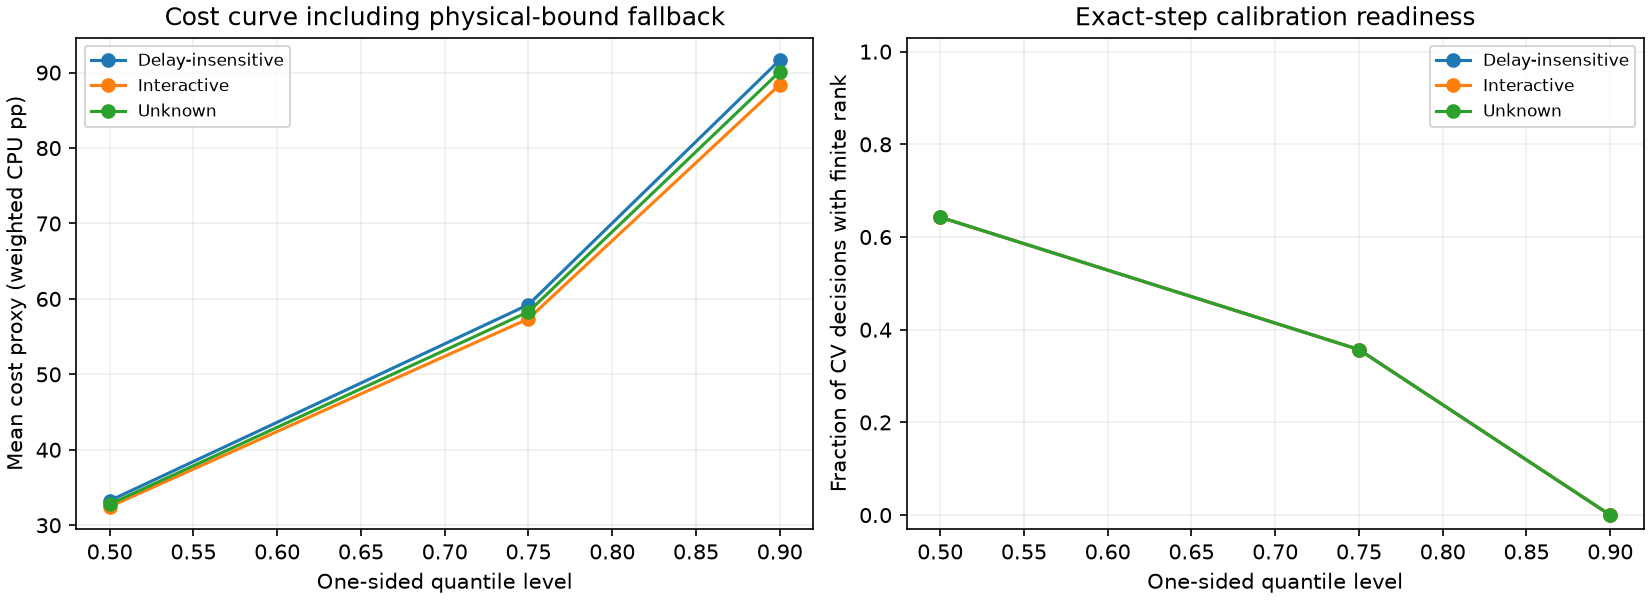

In [13]:
from cwfc.capacity import run as run_capacity
category,deployment=run_capacity(ROOT)
display(category)
deployment=pd.read_csv(ROOT/"artifacts/operational/category_capacity_deployment.csv")
display(deployment.loc[deployment.policy.eq("cost_ratio_default")].groupby("target").agg(
    minimum_residuals=("calibration_n","min"),supported_steps=("upper_supported","sum")))

display(Image(filename=str(ROOT/"reports/figures/category_capacity.png")))


## 13. Operational recommendation and limitations

Retain demand planning, monitoring and human review. The final model has better pooled MAE but weak regime-onset/high-load behavior. Low-use classifiers do not establish safe removal, and unsupported quantiles do not establish economical capacity. The short selected trace, correlated windows and viewed holdout require new independent operating periods before deployment.